<a href="https://colab.research.google.com/github/kristinalatish/machine-learning/blob/main/%D0%9B%D0%A02_3_%D0%9B%D0%B0%D1%82%D0%B8%D1%88.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 2_3
**Тема:** аналіз коефіцієнта народжуваності в регіонах України (1950-2019)

Виконала: Латиш Крістіна

### 1. Підключення бібліотек
pandas потрібен для роботи з таблицею, matplotlib для графіків, requests і StringIO для завантаження сторінки з Вікіпедії.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import requests
from io import StringIO

### 2. Зчитування таблиці
Сторінку завантажуємо через requests із заголовком User-Agent, бо без нього Вікіпедія може заблокувати запит.
Функція read_html шукає таблицю зі словом "народжуваності". На сторінці числа записані з комою (13,9), тому вказуємо decimal=",".

In [2]:
url = "https://uk.wikipedia.org/wiki/Населення_України"
headers = {"User-Agent": "Mozilla/5.0"}
page = requests.get(url, headers=headers)

tables = pd.read_html(StringIO(page.text), match="народжуваності", decimal=",", thousands=" ")
print("Знайдено таблиць:", len(tables))

data = tables[0]
data

Знайдено таблиць: 2


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—
5,Житомирська,26.1,22.3,15.9,12.9,8.9,12.2,12.0,7.9
6,Закарпатська,31.4,27.3,20.7,16.8,11.5,15.1,14.6,10.4
7,Запорізька,21.9,19.7,15.0,12.4,7.1,10.6,10.6,6.8
8,Івано-Франківська,24.3,24.8,18.2,15.5,10.3,12.4,12.2,8.8
9,Київська,20.4,18.9,15.6,12.3,7.3,12.2,12.1,8.0


### 3. Перший огляд даних
Дивимось, скільки рядків і колонок. Назви колонок переводимо в текст, щоб звертатись до них так: data["2019"].

In [3]:
print("Розмір таблиці:", data.shape)

data.columns = data.columns.astype(str)
print("Колонки:", list(data.columns))

Розмір таблиці: (28, 9)
Колонки: ['Регіон', '1950', '1960', '1970', '1990', '2000', '2012', '2014', '2019']


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Регіон  28 non-null     object 
 1   1950    26 non-null     float64
 2   1960    27 non-null     float64
 3   1970    27 non-null     float64
 4   1990    28 non-null     float64
 5   2000    28 non-null     float64
 6   2012    28 non-null     float64
 7   2014    28 non-null     object 
 8   2019    28 non-null     object 
dtypes: float64(6), object(3)
memory usage: 2.1+ KB


Колонки 2014 і 2019 мають тип object (текст), хоча там мають бути числа. Це через прочерки "—" там, де немає даних.

### 4. Перетворення в числа
pd.to_numeric переводить колонку в числа, а errors="coerce" замінює прочерки на NaN (пропуск).

In [5]:
data["2014"] = pd.to_numeric(data["2014"], errors="coerce")
data["2019"] = pd.to_numeric(data["2019"], errors="coerce")

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Регіон  28 non-null     object 
 1   1950    26 non-null     float64
 2   1960    27 non-null     float64
 3   1970    27 non-null     float64
 4   1990    28 non-null     float64
 5   2000    28 non-null     float64
 6   2012    28 non-null     float64
 7   2014    26 non-null     float64
 8   2019    24 non-null     float64
dtypes: float64(8), object(1)
memory usage: 2.1+ KB


### 5. Пропуски
Рахуємо кількість пропусків у кожній колонці і дивимось, в яких саме регіонах їх немає.

In [6]:
data.isnull().sum()

,0
Регіон,0
1950,2
1960,1
1970,1
1990,0
2000,0
2012,0
2014,2
2019,4


In [7]:
data[data.isnull().any(axis=1)]

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,NaN,NaN
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,NaN
11,Луганська,26.2,23.5,14.4,11.6,6.2,9.6,5.1,NaN
25,Київ,NaN,17.4,15.9,12.0,7.3,12.0,12.1,11.0
26,Севастополь,NaN,NaN,NaN,12.5,7.0,12.0,NaN,NaN


### 6. Відділяємо рядок "Україна"
Останній рядок це дані по всій країні, а не регіон. Зберігаємо його окремо, щоб порівнювати з ним регіони, а в таблиці регіонів залишаємо тільки області і міста.

In [8]:
ukraine = data[data["Регіон"] == "Україна"]
regions = data[data["Регіон"] != "Україна"]

print("Кількість регіонів:", len(regions))
ukraine

Кількість регіонів: 27


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
27,Україна,22.8,20.5,15.2,12.6,7.8,11.4,11.1,8.1


### 7. Видаляємо регіони з пропусками
Пропуски не заповнюємо вигаданими числами, а прибираємо ці регіони з аналізу. Їх небагато, тому на загальну картину це майже не впливає.
Мінус такого способу: випадає Київ, бо по ньому немає даних за 1950 рік.

In [9]:
regions_clean = regions.dropna()

print("Було регіонів:", len(regions))
print("Залишилось:", len(regions_clean))

Було регіонів: 27
Залишилось: 22


### 8. Описова статистика
describe() показує по кожному року середнє, мінімум, максимум і т.д.

In [10]:
regions_clean.describe().round(2)

,1950,1960,1970,1990,2000,2012,2014,2019
count,22.00,22.00,22.00,22.00,22.00,22.00,22.00,22.00
mean,22.79,20.76,15.70,13.30,8.55,11.76,11.51,7.88
std,2.86,3.12,2.03,1.59,1.56,1.73,1.58,1.36
min,18.60,16.30,12.70,10.80,6.80,9.40,9.00,6.00
25%,20.88,18.52,14.42,12.30,7.15,10.70,10.65,6.80
50%,21.95,19.75,15.30,12.75,8.20,11.40,11.20,7.75
75%,24.25,22.18,16.90,14.28,9.17,12.35,12.18,8.78
max,31.40,27.30,20.70,16.80,11.80,15.90,14.80,10.70


### 9. Найвища і найнижча народжуваність у 2019 році

In [11]:
max_2019 = regions_clean["2019"].max()
min_2019 = regions_clean["2019"].min()

print("Найвища:")
print(regions_clean[regions_clean["2019"] == max_2019][["Регіон", "2019"]])
print()
print("Найнижча:")
print(regions_clean[regions_clean["2019"] == min_2019][["Регіон", "2019"]])

Найвища:
        Регіон  2019
16  Рівненська  10.7

Найнижча:
     Регіон  2019
17  Сумська   6.0


### 10. Як змінилась народжуваність по Україні
Списки років робимо вручну: years для назв колонок, years_num для осі X на графіках (щоб відстані між роками були правильні).

In [12]:
years = ["1950", "1960", "1970", "1990", "2000", "2012", "2014", "2019"]
years_num = [1950, 1960, 1970, 1990, 2000, 2012, 2014, 2019]

ukr_values = ukraine[years].values[0]
print(ukr_values)

print("У 1950:", ukr_values[0])
print("У 2019:", ukr_values[-1])
print("Зменшилась у", round(ukr_values[0] / ukr_values[-1], 2), "раза")

[22.8 20.5 15.2 12.6  7.8 11.4 11.1  8.1]
У 1950: 22.8
У 2019: 8.1
Зменшилась у 2.81 раза


### 11. Регіони, де у 2019 народжуваність вища, ніж по Україні

In [13]:
ukr_2019 = ukr_values[-1]
print("По Україні у 2019:", ukr_2019)

higher = regions_clean[regions_clean["2019"] > ukr_2019]
higher[["Регіон", "2019"]].sort_values("2019", ascending=False)

По Україні у 2019: 8.1


,Регіон,2019
16,Рівненська,10.7
6,Закарпатська,10.4
2,Волинська,10.1
23,Чернівецька,9.2
8,Івано-Франківська,8.8
14,Одеська,8.8
12,Львівська,8.7


## Графіки

**Графік 1.** Народжуваність по Україні за всі роки. Показує загальну тенденцію.

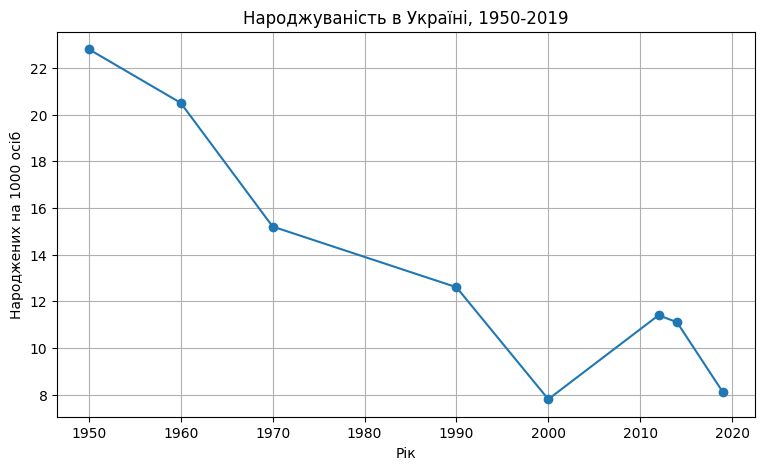

In [14]:
plt.figure(figsize=(9, 5))
plt.plot(years_num, ukr_values, marker="o")
plt.title("Народжуваність в Україні, 1950-2019")
plt.xlabel("Рік")
plt.ylabel("Народжених на 1000 осіб")
plt.grid()
plt.show()

**Графік 2.** 5 регіонів з найвищою і 5 з найнижчою народжуваністю у 2019. Червона лінія це рівень по Україні.

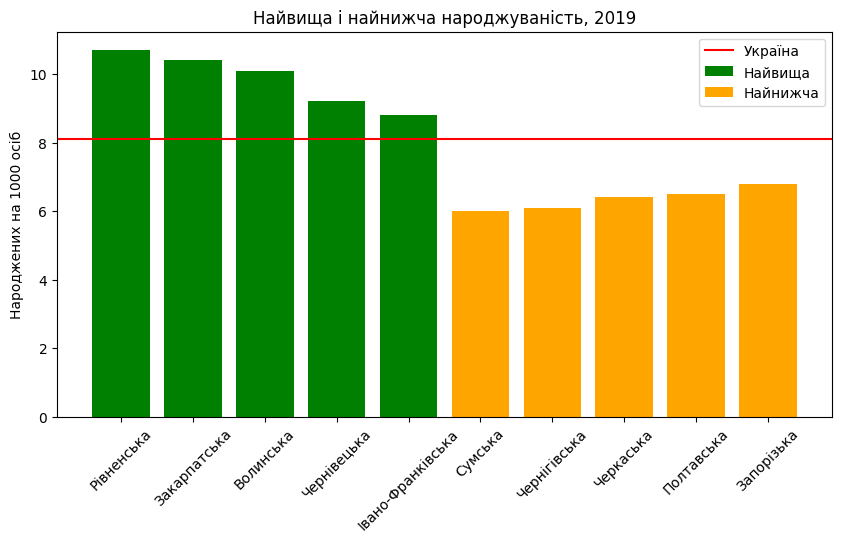

In [15]:
top5 = regions_clean.sort_values("2019", ascending=False).head(5)
bottom5 = regions_clean.sort_values("2019").head(5)

plt.figure(figsize=(10, 5))
plt.bar(top5["Регіон"], top5["2019"], color="green", label="Найвища")
plt.bar(bottom5["Регіон"], bottom5["2019"], color="orange", label="Найнижча")
plt.axhline(ukr_2019, color="red", label="Україна")
plt.title("Найвища і найнижча народжуваність, 2019")
plt.ylabel("Народжених на 1000 осіб")
plt.xticks(rotation=45)
plt.legend()
plt.show()

**Графік 3.** Динаміка в п'яти регіонах з різних частин країни: захід, схід, південь, північ і центр.

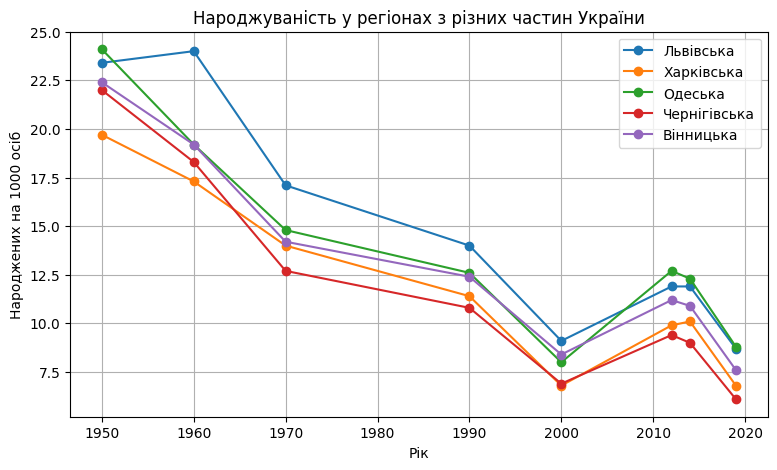

In [16]:
chosen = ["Львівська", "Харківська", "Одеська", "Чернігівська", "Вінницька"]

plt.figure(figsize=(9, 5))
for name in chosen:
    row = regions_clean[regions_clean["Регіон"] == name]
    plt.plot(years_num, row[years].values[0], marker="o", label=name)
plt.title("Народжуваність у регіонах з різних частин України")
plt.xlabel("Рік")
plt.ylabel("Народжених на 1000 осіб")
plt.legend()
plt.grid()
plt.show()

**Графік 4.** Порівняння 1990 і 2019 років. Кожна точка це регіон. Якщо точки йдуть знизу вліво вгору вправо, значить регіони з високою народжуваністю у 1990 і у 2019 залишились лідерами.

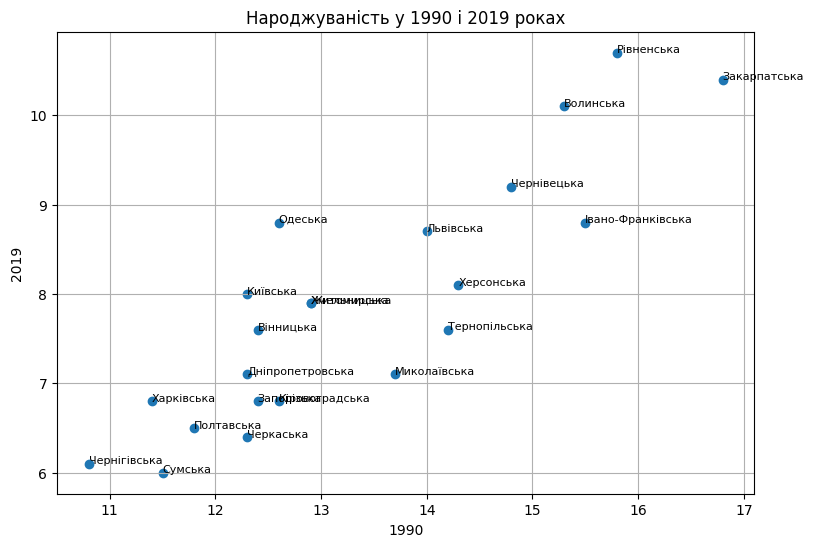

In [17]:
plt.figure(figsize=(9, 6))
plt.scatter(regions_clean["1990"], regions_clean["2019"])

for name, x, y in zip(regions_clean["Регіон"], regions_clean["1990"], regions_clean["2019"]):
    plt.text(x, y, name, fontsize=8)

plt.title("Народжуваність у 1990 і 2019 роках")
plt.xlabel("1990")
plt.ylabel("2019")
plt.grid()
plt.show()

**Графік 5.** Гістограма значень по регіонах у 1950 і 2019. Видно, наскільки змістились значення і наскільки великий розкид між регіонами.

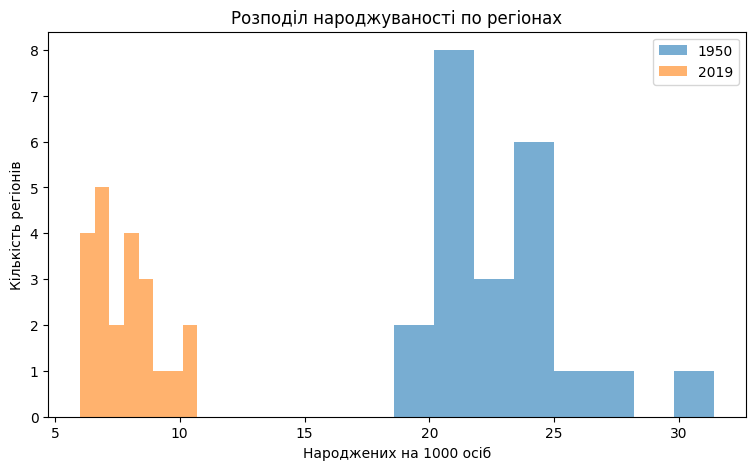

In [18]:
plt.figure(figsize=(9, 5))
plt.hist(regions_clean["1950"], bins=8, alpha=0.6, label="1950")
plt.hist(regions_clean["2019"], bins=8, alpha=0.6, label="2019")
plt.title("Розподіл народжуваності по регіонах")
plt.xlabel("Народжених на 1000 осіб")
plt.ylabel("Кількість регіонів")
plt.legend()
plt.show()

## Висновки

1. За 1950-2019 народжуваність в Україні зменшилась з 22.8 до 8.1 на 1000 осіб, тобто приблизно у 2.8 раза.
2. Падіння було нерівномірним: найнижче значення у 2000 році (7.8), потім до 2012 був ріст до 11.4, а після 2014 знову спад.
3. У таблиці були пропуски по Криму, Севастополю, Донецькій, Луганській областях і Києву. Ці регіони прибрали з аналізу, залишилось 22 регіони.
4. У 2019 найвища народжуваність у Рівненській області (10.7), найнижча у Сумській (6). Вище за рівень України в основному західні області (Рівненська, Закарпатська, Волинська, Чернівецька, Івано-Франківська, Львівська) та Одеська.
5. На графіку 3 серед вибраних регіонів Чернігівська у 2019 найнижча (6.1) і впала найбільше, з 22.0. Львівська та Одеська тримаються вище за інші.
6. Графік 4 показує, що регіони з високою народжуваністю у 1990 залишились лідерами і у 2019, тобто різниця між заходом і рештою країни зберігається.
7. За гістограмою у 1950 значення по регіонах були приблизно від 19 до 31.4, а у 2019 приблизно від 6 до 10.7. Народжуваність знизилась у всіх регіонах, і різниця між ними стала меншою.